In [1]:

import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn
import xgboost

from sklearn.model_selection import train_test_split
from sklearn.base import clone

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    OrdinalEncoder
)

from sklearn.linear_model import (
    LogisticRegression,
    LinearRegression,
    Ridge,
    Lasso
)

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.cluster import KMeans
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    silhouette_score
)

from joblib import dump

warnings.filterwarnings("ignore")

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.feature_engineering import LoanFeatureEngineer

print("Libraries imported successfully!")
print("Scikit-learn version:", sklearn.__version__)
print("XGBoost version:", xgboost.__version__)
print("Project root:", PROJECT_ROOT)


Libraries imported successfully!
Scikit-learn version: 1.9.1
XGBoost version: 3.4.1
Project root: c:\Users\Admin\Desktop\python_new\github\week-2-weekly-assessment


In [2]:

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "lending_club_loans.csv"
)

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset shape: (396030, 27)


,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,...,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,application_type,mort_acc,pub_rec_bankruptcies,address
0,10000.0,36 months,11.44,329.48,B,B4,Marketing,10+ years,RENT,117000.0,...,16.0,0.0,36369.0,41.8,25.0,w,INDIVIDUAL,0.0,0.0,"0174 Michelle Gateway\r\nMendozaberg, OK 22690"
1,8000.0,36 months,11.99,265.68,B,B5,Credit analyst,4 years,MORTGAGE,65000.0,...,17.0,0.0,20131.0,53.3,27.0,f,INDIVIDUAL,3.0,0.0,"1076 Carney Fort Apt. 347\r\nLoganmouth, SD 05113"
2,15600.0,36 months,10.49,506.97,B,B3,Statistician,< 1 year,RENT,43057.0,...,13.0,0.0,11987.0,92.2,26.0,f,INDIVIDUAL,0.0,0.0,"87025 Mark Dale Apt. 269\r\nNew Sabrina, WV 05113"
3,7200.0,36 months,6.49,220.65,A,A2,Client Advocate,6 years,RENT,54000.0,...,6.0,0.0,5472.0,21.5,13.0,f,INDIVIDUAL,0.0,0.0,"823 Reid Ford\r\nDelacruzside, MA 00813"
4,24375.0,60 months,17.27,609.33,C,C5,Destiny Management Inc.,9 years,MORTGAGE,55000.0,...,13.0,0.0,24584.0,69.8,43.0,f,INDIVIDUAL,1.0,0.0,"679 Luna Roads\r\nGreggshire, VA 11650"


In [3]:

df["default"] = (
    df["loan_status"] == "Charged Off"
).astype(int)

print("Target distribution:")
print(df["default"].value_counts())

print("\nTarget percentage:")
print(df["default"].value_counts(normalize=True) * 100)


Target distribution:
default
0    318357
1     77673
Name: count, dtype: int64

Target percentage:
default
0    80.387092
1    19.612908
Name: proportion, dtype: float64


In [ ]:

feature_cols = [
    "loan_amnt",
    "term",
    "int_rate",
    "installment",
    "grade",
    "sub_grade",
    "emp_length",
    "home_ownership",
    "annual_inc",
    "verification_status",
    "purpose",
    "issue_d",
    "earliest_cr_line",
    "dti",
    "open_acc",
    "pub_rec",
    "revol_bal",
    "revol_util",
    "total_acc",
    "initial_list_status",
    "application_type",
    "mort_acc",
    "pub_rec_bankruptcies"
]

X = df[feature_cols].copy()
y = df["default"].copy()

print("Feature shape:", X.shape)
print("Target shape:", y.shape)


Feature shape: (396030, 23)
Target shape: (396030,)


In [5]:

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)


Training: (237618, 23)
Validation: (79206, 23)
Testing: (79206, 23)


In [6]:

numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

onehot_features = [
    "term",
    "emp_length",
    "home_ownership",
    "verification_status",
    "purpose",
    "initial_list_status",
    "application_type"
]

ordinal_features = [
    "grade",
    "sub_grade"
]

grade_categories = [
    "A", "B", "C", "D", "E", "F", "G"
]

sub_grade_categories = [
    f"{grade}{number}"
    for grade in "ABCDEFG"
    for number in range(1, 6)
]

ordinal_categories = [
    grade_categories,
    sub_grade_categories
]

engineered_numeric_features = numeric_features + [
    "issue_year",
    "issue_month",
    "credit_history_months",
    "income_to_loan_ratio",
    "log_annual_inc"
]

print("Numeric features:", numeric_features)
print("One-hot features:", onehot_features)
print("Ordinal features:", ordinal_features)


Numeric features: ['loan_amnt', 'int_rate', 'installment', 'annual_inc', 'dti', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'mort_acc', 'pub_rec_bankruptcies']
One-hot features: ['term', 'emp_length', 'home_ownership', 'verification_status', 'purpose', 'initial_list_status', 'application_type']
Ordinal features: ['grade', 'sub_grade']


In [7]:

numeric_transformer = Pipeline(steps=[
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    )
])

onehot_transformer = Pipeline(steps=[
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "encoder",
        OneHotEncoder(handle_unknown="ignore")
    )
])

ordinal_transformer = Pipeline(steps=[
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "encoder",
        OrdinalEncoder(
            categories=ordinal_categories,
            handle_unknown="use_encoded_value",
            unknown_value=-1
        )
    )
])

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_transformer,
            engineered_numeric_features
        ),
        (
            "categorical",
            onehot_transformer,
            onehot_features
        ),
        (
            "ordinal",
            ordinal_transformer,
            ordinal_features
        )
    ],
    remainder="drop"
)

print("Preprocessor created successfully!")


Preprocessor created successfully!


In [8]:

def create_classification_pipeline(classifier):

    pipeline = Pipeline(steps=[
        (
            "feature_engineering",
            LoanFeatureEngineer()
        ),
        (
            "preprocessor",
            clone(preprocessor)
        ),
        (
            "classifier",
            classifier
        )
    ])

    return pipeline


print("Classification pipeline function created!")


Classification pipeline function created!


In [9]:

logistic_pipeline = create_classification_pipeline(
    LogisticRegression(
        max_iter=1000,
        random_state=42
    )
)

logistic_pipeline.fit(
    X_train,
    y_train
)

logistic_predictions = logistic_pipeline.predict(X_val)

logistic_accuracy = accuracy_score(
    y_val,
    logistic_predictions
)

logistic_f1 = f1_score(
    y_val,
    logistic_predictions
)

logistic_recall = recall_score(
    y_val,
    logistic_predictions
)

print("Logistic Regression Results")
print("----------------------------")
print("Validation Accuracy:", logistic_accuracy)
print("Validation F1 Score:", logistic_f1)
print("Validation Recall:", logistic_recall)


Logistic Regression Results
----------------------------
Validation Accuracy: 0.8062899275307426
Validation F1 Score: 0.15105405854036408
Validation Recall: 0.08786610878661087


In [10]:

decision_tree_pipeline = create_classification_pipeline(
    DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=20,
        random_state=42
    )
)

decision_tree_pipeline.fit(
    X_train,
    y_train
)

decision_tree_predictions = decision_tree_pipeline.predict(X_val)

decision_tree_accuracy = accuracy_score(
    y_val,
    decision_tree_predictions
)

decision_tree_f1 = f1_score(
    y_val,
    decision_tree_predictions
)

decision_tree_recall = recall_score(
    y_val,
    decision_tree_predictions
)

print("Decision Tree Results")
print("---------------------")
print("Validation Accuracy:", decision_tree_accuracy)
print("Validation F1 Score:", decision_tree_f1)
print("Validation Recall:", decision_tree_recall)


Decision Tree Results
---------------------
Validation Accuracy: 0.8049642703835568
Validation F1 Score: 0.08156956004756243
Validation Recall: 0.0441583521081429


In [11]:

random_forest_pipeline = create_classification_pipeline(
    RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_leaf=2,
        max_features="sqrt",
        bootstrap=True,
        oob_score=True,
        n_jobs=-1,
        random_state=42
    )
)

random_forest_pipeline.fit(
    X_train,
    y_train
)

random_forest_predictions = random_forest_pipeline.predict(X_val)

random_forest_accuracy = accuracy_score(
    y_val,
    random_forest_predictions
)

random_forest_f1 = f1_score(
    y_val,
    random_forest_predictions
)

random_forest_recall = recall_score(
    y_val,
    random_forest_predictions
)

random_forest_oob = (
    random_forest_pipeline
    .named_steps["classifier"]
    .oob_score_
)

print("Random Forest Results")
print("---------------------")
print("Validation Accuracy:", random_forest_accuracy)
print("Validation F1 Score:", random_forest_f1)
print("Validation Recall:", random_forest_recall)
print("OOB Score:", random_forest_oob)


Random Forest Results
---------------------
Validation Accuracy: 0.8077039618210742
Validation F1 Score: 0.11277450923283043
Validation Recall: 0.0623109108464757
OOB Score: 0.8070684880775025


In [12]:

xgb_feature_engineer = LoanFeatureEngineer()

X_train_engineered = xgb_feature_engineer.fit_transform(
    X_train
)

X_val_engineered = xgb_feature_engineer.transform(
    X_val
)

xgb_preprocessor = clone(preprocessor)

X_train_processed = xgb_preprocessor.fit_transform(
    X_train_engineered,
    y_train
)

X_val_processed = xgb_preprocessor.transform(
    X_val_engineered
)

print("Training transformed shape:", X_train_processed.shape)
print("Validation transformed shape:", X_val_processed.shape)


Training transformed shape: (237618, 60)
Validation transformed shape: (79206, 60)


In [13]:

xgb_model = XGBClassifier(
    n_estimators=500,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    early_stopping_rounds=30,
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

xgb_model.fit(
    X_train_processed,
    y_train,
    eval_set=[
        (X_val_processed, y_val)
    ],
    verbose=False
)

print("XGBoost training completed!")
print("Best iteration:", xgb_model.best_iteration)
print("Best validation score:", xgb_model.best_score)


XGBoost training completed!
Best iteration: 495
Best validation score: 0.4370687726867802


In [14]:

xgb_predictions = xgb_model.predict(
    X_val_processed
)

xgb_accuracy = accuracy_score(
    y_val,
    xgb_predictions
)

xgb_f1 = f1_score(
    y_val,
    xgb_predictions
)

xgb_recall = recall_score(
    y_val,
    xgb_predictions
)

print("XGBoost Results")
print("---------------")
print("Validation Accuracy:", xgb_accuracy)
print("Validation F1 Score:", xgb_f1)
print("Validation Recall:", xgb_recall)


XGBoost Results
---------------
Validation Accuracy: 0.8091684973360604
Validation F1 Score: 0.17759399314434954
Validation Recall: 0.10505310588992597


In [15]:

classification_results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Validation Accuracy": logistic_accuracy,
        "Validation F1": logistic_f1,
        "Validation Recall": logistic_recall
    },
    {
        "Model": "Decision Tree",
        "Validation Accuracy": decision_tree_accuracy,
        "Validation F1": decision_tree_f1,
        "Validation Recall": decision_tree_recall
    },
    {
        "Model": "Random Forest",
        "Validation Accuracy": random_forest_accuracy,
        "Validation F1": random_forest_f1,
        "Validation Recall": random_forest_recall
    },
    {
        "Model": "XGBoost",
        "Validation Accuracy": xgb_accuracy,
        "Validation F1": xgb_f1,
        "Validation Recall": xgb_recall
    }
])

classification_results = classification_results.sort_values(
    by="Validation F1",
    ascending=False
).reset_index(drop=True)

display(
    classification_results.style.format({
        "Validation Accuracy": "{:.4f}",
        "Validation F1": "{:.4f}",
        "Validation Recall": "{:.4f}"
    })
)


,Model,Validation Accuracy,Validation F1,Validation Recall
0,XGBoost,0.8092,0.1776,0.1051
1,Logistic Regression,0.8063,0.1511,0.0879
2,Random Forest,0.8077,0.1128,0.0623
3,Decision Tree,0.8050,0.0816,0.0442


In [16]:

five_records = X_val.sample(
    n=5,
    random_state=42
)

logistic_class_predictions = logistic_pipeline.predict(
    five_records
)

logistic_probabilities = logistic_pipeline.predict_proba(
    five_records
)

probability_results = five_records[
    ["loan_amnt", "annual_inc", "int_rate"]
].copy()

probability_results["predict()"] = logistic_class_predictions

probability_results["Fully Paid Probability"] = (
    logistic_probabilities[:, 0]
)

probability_results["Charged Off Probability"] = (
    logistic_probabilities[:, 1]
)

probability_results["Probability Based Prediction"] = np.where(
    logistic_probabilities[:, 1] >= 0.5,
    1,
    0
)

probability_results["Predicted Status"] = (
    probability_results["predict()"]
    .map({
        0: "Fully Paid",
        1: "Charged Off"
    })
)

display(
    probability_results.style.format({
        "Fully Paid Probability": "{:.4f}",
        "Charged Off Probability": "{:.4f}"
    })
)


,loan_amnt,annual_inc,int_rate,predict(),Fully Paid Probability,Charged Off Probability,Probability Based Prediction,Predicted Status
348844,7000.000000,48000.000000,6.620000,0,0.9180,0.0820,0,Fully Paid
42914,19200.000000,100000.000000,6.970000,0,0.9307,0.0693,0,Fully Paid
308946,20000.000000,61000.000000,12.120000,0,0.8135,0.1865,0,Fully Paid
200626,3700.000000,45200.000000,13.350000,0,0.8423,0.1577,0,Fully Paid
290780,18000.000000,100950.000000,12.290000,0,0.8977,0.1023,0,Fully Paid


In [17]:

print(
    "Are predict() and probability-based predictions identical?",
    np.array_equal(
        logistic_class_predictions,
        probability_results[
            "Probability Based Prediction"
        ].to_numpy()
    )
)


Are predict() and probability-based predictions identical? True


In [18]:

rf_feature_engineer = (
    random_forest_pipeline
    .named_steps["feature_engineering"]
)

rf_preprocessor = (
    random_forest_pipeline
    .named_steps["preprocessor"]
)

rf_classifier = (
    random_forest_pipeline
    .named_steps["classifier"]
)

rf_feature_names = rf_preprocessor.get_feature_names_out()

rf_importance = pd.DataFrame({
    "Feature": rf_feature_names,
    "Importance": rf_classifier.feature_importances_
})

rf_importance = rf_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

top_5_rf = rf_importance.head(5)

print("Top 5 Random Forest Features:")
display(top_5_rf)


Top 5 Random Forest Features:


,Feature,Importance
0,ordinal__sub_grade,0.096096
1,numeric__int_rate,0.082230
2,numeric__dti,0.068250
3,ordinal__grade,0.067233
4,numeric__income_to_loan_ratio,0.061952


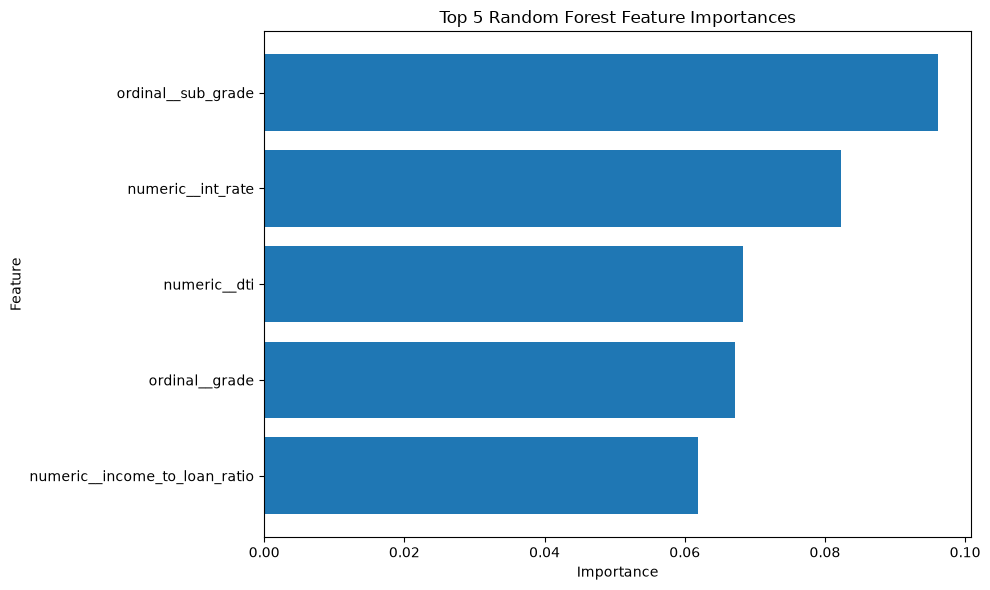

In [19]:

plt.figure(figsize=(10, 6))

plt.barh(
    top_5_rf["Feature"][::-1],
    top_5_rf["Importance"][::-1]
)

plt.title("Top 5 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()


In [20]:

xgb_feature_names = xgb_preprocessor.get_feature_names_out()

xgb_importance = pd.DataFrame({
    "Feature": xgb_feature_names,
    "Importance": xgb_model.feature_importances_
})

xgb_importance = xgb_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

top_5_xgb = xgb_importance.head(5)

print("Top 5 XGBoost Features:")
display(top_5_xgb)


Top 5 XGBoost Features:


,Feature,Importance
0,ordinal__sub_grade,0.192456
1,ordinal__grade,0.184844
2,categorical__term_ 36 months,0.060184
3,numeric__int_rate,0.035574
4,categorical__term_ 60 months,0.034089


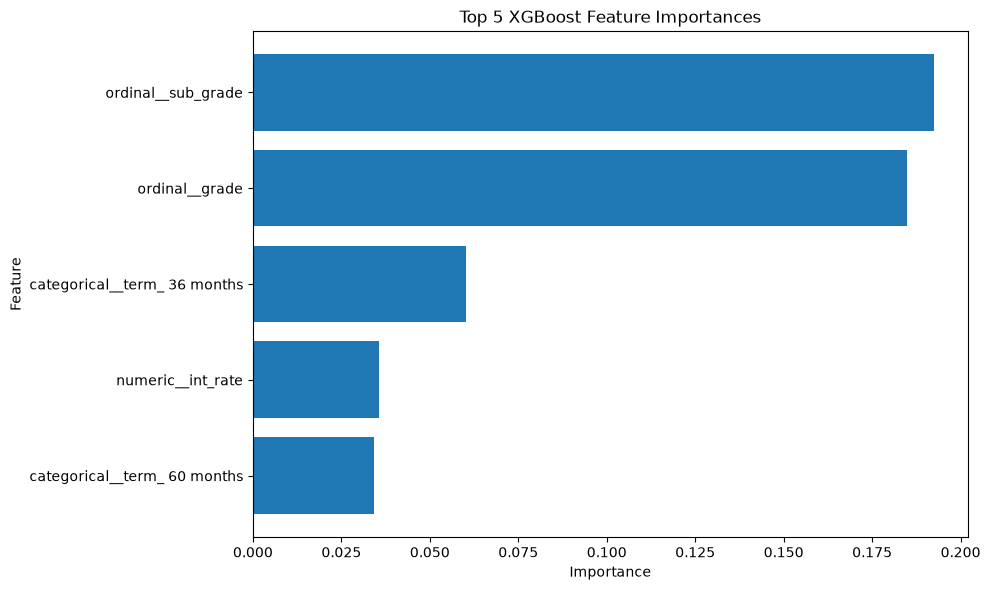

In [21]:

plt.figure(figsize=(10, 6))

plt.barh(
    top_5_xgb["Feature"][::-1],
    top_5_xgb["Importance"][::-1]
)

plt.title("Top 5 XGBoost Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()


In [22]:

regression_target = df["loan_amnt"].copy()

regression_numeric_features = [
    "annual_inc",
    "dti",
    "open_acc",
    "pub_rec",
    "revol_bal",
    "revol_util",
    "total_acc",
    "mort_acc",
    "pub_rec_bankruptcies"
]

regression_categorical_features = [
    "term",
    "emp_length",
    "home_ownership",
    "verification_status",
    "purpose",
    "initial_list_status",
    "application_type"
]

regression_feature_cols = (
    regression_numeric_features
    + regression_categorical_features
)

X_reg = df[regression_feature_cols].copy()
y_reg = regression_target

print("Regression feature shape:", X_reg.shape)
print("Regression target shape:", y_reg.shape)

print("\nRegression target summary:")
print(y_reg.describe())


Regression feature shape: (396030, 16)
Regression target shape: (396030,)

Regression target summary:
count    396030.000000
mean      14113.888089
std        8357.441341
min         500.000000
25%        8000.000000
50%       12000.000000
75%       20000.000000
max       40000.000000
Name: loan_amnt, dtype: float64


In [23]:

X_reg_train = X_reg.loc[X_train.index]
X_reg_val = X_reg.loc[X_val.index]

y_reg_train = y_reg.loc[X_train.index]
y_reg_val = y_reg.loc[X_val.index]

print("Regression training:", X_reg_train.shape)
print("Regression validation:", X_reg_val.shape)


Regression training: (237618, 16)
Regression validation: (79206, 16)


In [24]:

regression_numeric_transformer = Pipeline(steps=[
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    )
])

regression_categorical_transformer = Pipeline(steps=[
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "encoder",
        OneHotEncoder(handle_unknown="ignore")
    )
])

regression_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            regression_numeric_transformer,
            regression_numeric_features
        ),
        (
            "categorical",
            regression_categorical_transformer,
            regression_categorical_features
        )
    ],
    remainder="drop"
)

print("Regression preprocessor created!")


Regression preprocessor created!


In [25]:

X_reg_train_processed = regression_preprocessor.fit_transform(
    X_reg_train
)

X_reg_val_processed = regression_preprocessor.transform(
    X_reg_val
)

print("Processed training shape:", X_reg_train_processed.shape)
print("Processed validation shape:", X_reg_val_processed.shape)


Processed training shape: (237618, 50)
Processed validation shape: (79206, 50)


In [26]:

linear_model = LinearRegression()

linear_model.fit(
    X_reg_train_processed,
    y_reg_train
)

linear_predictions = linear_model.predict(
    X_reg_val_processed
)

print("Linear Regression completed!")
print("First five predictions:", linear_predictions[:5])


Linear Regression completed!
First five predictions: [ 8682.86817665 14696.79231956 10118.70213349 19814.92124863
  9848.67008425]


In [27]:

ridge_model = Ridge(
    alpha=10.0
)

ridge_model.fit(
    X_reg_train_processed,
    y_reg_train
)

ridge_predictions = ridge_model.predict(
    X_reg_val_processed
)

print("Ridge Regression completed!")
print("First five predictions:", ridge_predictions[:5])


Ridge Regression completed!
First five predictions: [ 8682.74560738 14696.48237065 10118.52925515 19814.71019375
  9848.91668895]


In [28]:

lasso_model = Lasso(
    alpha=10.0,
    max_iter=10000
)

lasso_model.fit(
    X_reg_train_processed,
    y_reg_train
)

lasso_predictions = lasso_model.predict(
    X_reg_val_processed
)

print("Lasso Regression completed!")
print("First five predictions:", lasso_predictions[:5])


Lasso Regression completed!
First five predictions: [ 8608.75475825 14759.5056861  10126.76477705 19726.2508276
  9659.45109232]


In [29]:

regression_feature_names = (
    regression_preprocessor.get_feature_names_out()
)

coefficient_comparison = pd.DataFrame({
    "Feature": regression_feature_names,
    "Linear Regression": linear_model.coef_,
    "Ridge": ridge_model.coef_,
    "Lasso": lasso_model.coef_
})

display(
    coefficient_comparison.head(20).style.format({
        "Linear Regression": "{:.4f}",
        "Ridge": "{:.4f}",
        "Lasso": "{:.4f}"
    })
)


,Feature,Linear Regression,Ridge,Lasso
0,numeric__annual_inc,1931.5443,1931.5507,1936.0386
1,numeric__dti,-100.4459,-100.2238,-78.8832
2,numeric__open_acc,396.4922,396.4494,392.7516
3,numeric__pub_rec,-138.6791,-138.6607,-129.7971
4,numeric__revol_bal,1211.9682,1211.9537,1213.5984
5,numeric__revol_util,119.5287,119.6421,110.9801
6,numeric__total_acc,274.3463,274.3971,271.7565
7,numeric__mort_acc,474.5952,474.6223,477.4961
8,numeric__pub_rec_bankruptcies,-567.1335,-567.0804,-560.2330
9,categorical__term_ 36 months,-2903.8839,-2903.7870,-5796.9218


In [30]:

lasso_zero_count = np.sum(
    np.isclose(lasso_model.coef_, 0.0)
)

total_coefficients = len(lasso_model.coef_)

print("Total coefficients:", total_coefficients)
print("Lasso zero coefficients:", lasso_zero_count)

print(
    "Percentage of zero coefficients:",
    (lasso_zero_count / total_coefficients) * 100
)


Total coefficients: 50
Lasso zero coefficients: 22
Percentage of zero coefficients: 44.0


In [31]:

regression_results = pd.DataFrame([
    {
        "Model": "Linear Regression",
        "Validation R2": linear_model.score(
            X_reg_val_processed,
            y_reg_val
        )
    },
    {
        "Model": "Ridge Regression",
        "Validation R2": ridge_model.score(
            X_reg_val_processed,
            y_reg_val
        )
    },
    {
        "Model": "Lasso Regression",
        "Validation R2": lasso_model.score(
            X_reg_val_processed,
            y_reg_val
        )
    }
])

display(
    regression_results.style.format({
        "Validation R2": "{:.4f}"
    })
)


,Model,Validation R2
0,Linear Regression,0.3855
1,Ridge Regression,0.3855
2,Lasso Regression,0.3838


In [32]:

cluster_features = [
    "annual_inc",
    "dti",
    "revol_bal"
]

cluster_data = X_train[cluster_features].copy()

cluster_data = cluster_data.sample(
    n=min(20000, len(cluster_data)),
    random_state=42
)

cluster_imputer = SimpleImputer(
    strategy="median"
)

cluster_scaler = StandardScaler()

cluster_imputed = cluster_imputer.fit_transform(
    cluster_data
)

cluster_scaled = cluster_scaler.fit_transform(
    cluster_imputed
)

print("Clustering data shape:", cluster_scaled.shape)
print("Features used:", cluster_features)


Clustering data shape: (20000, 3)
Features used: ['annual_inc', 'dti', 'revol_bal']


In [36]:

k_values = range(2, 9)

inertia_values = []
silhouette_values = []

rng = np.random.default_rng(42)

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(
        cluster_scaled
    )

    # Store inertia
    inertia_values.append(
        kmeans.inertia_
    )

    # Select a sample from every cluster
    sample_indices = []

    for cluster_id in np.unique(cluster_labels):

        cluster_indices = np.where(
            cluster_labels == cluster_id
        )[0]

        sample_size = min(
            500,
            len(cluster_indices)
        )

        selected_indices = rng.choice(
            cluster_indices,
            size=sample_size,
            replace=False
        )

        sample_indices.extend(selected_indices)

    sample_indices = np.array(sample_indices)

    # Calculate silhouette score using the balanced sample
    sampled_labels = cluster_labels[sample_indices]

    score = silhouette_score(
        cluster_scaled[sample_indices],
        sampled_labels
    )

    silhouette_values.append(score)

    print(
        f"k={k} | "
        f"Inertia={kmeans.inertia_:.2f} | "
        f"Silhouette={score:.4f}"
    )

print("\nK-Means evaluation completed successfully!")


k=2 | Inertia=40258.60 | Silhouette=0.9911
k=3 | Inertia=30022.82 | Silhouette=0.9834
k=4 | Inertia=21386.87 | Silhouette=0.8722
k=5 | Inertia=15197.51 | Silhouette=0.3954
k=6 | Inertia=11541.58 | Silhouette=0.3365
k=7 | Inertia=9700.64 | Silhouette=0.3635
k=8 | Inertia=8238.41 | Silhouette=0.3632

K-Means evaluation completed successfully!


In [37]:

clustering_results = pd.DataFrame({
    "Number of Clusters (k)": list(k_values),
    "Inertia": inertia_values,
    "Silhouette Score": silhouette_values
})

display(
    clustering_results.style.format({
        "Inertia": "{:,.2f}",
        "Silhouette Score": "{:.4f}"
    })
)


,Number of Clusters (k),Inertia,Silhouette Score
0,2,"40,258.60",0.9911
1,3,"30,022.82",0.9834
2,4,"21,386.87",0.8722
3,5,"15,197.51",0.3954
4,6,"11,541.58",0.3365
5,7,"9,700.64",0.3635
6,8,"8,238.41",0.3632


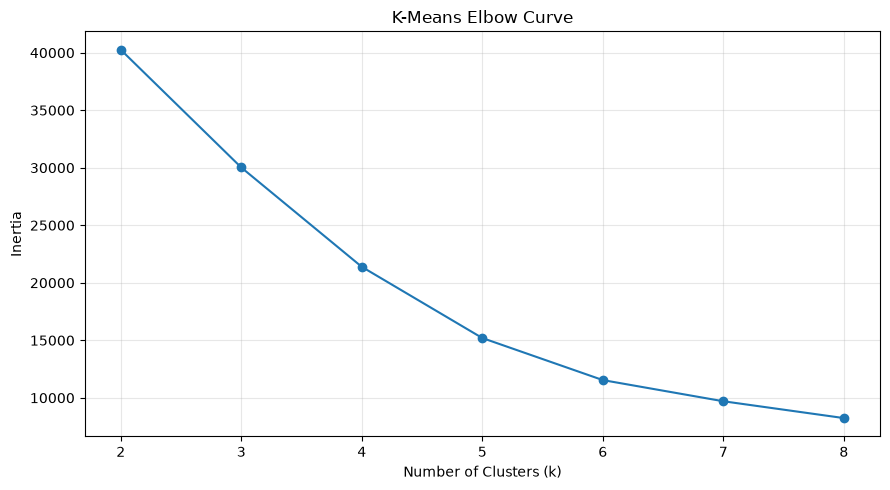

In [38]:

plt.figure(figsize=(9, 5))

plt.plot(
    list(k_values),
    inertia_values,
    marker="o"
)

plt.title("K-Means Elbow Curve")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")

plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


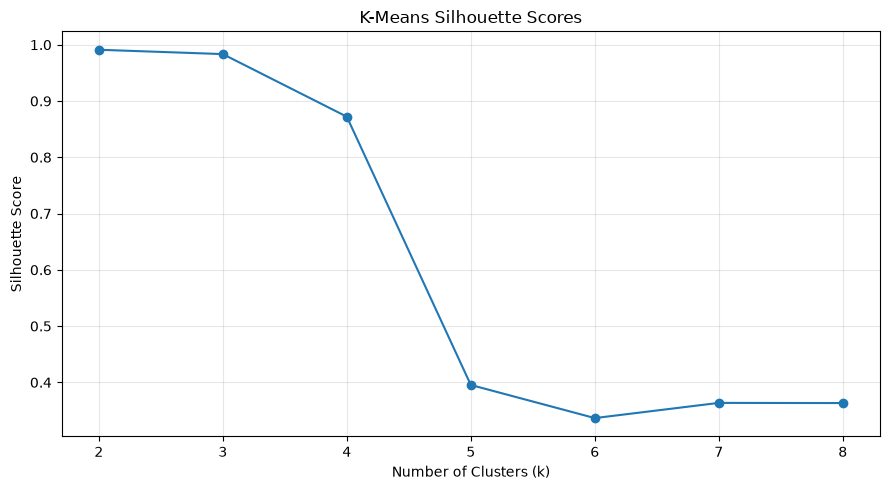

In [39]:

plt.figure(figsize=(9, 5))

plt.plot(
    list(k_values),
    silhouette_values,
    marker="o"
)

plt.title("K-Means Silhouette Scores")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")

plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [40]:

best_k_index = int(
    np.argmax(silhouette_values)
)

best_k = list(k_values)[best_k_index]

print("Best k based on silhouette score:", best_k)
print(
    "Best silhouette score:",
    silhouette_values[best_k_index]
)

final_kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

final_cluster_labels = final_kmeans.fit_predict(
    cluster_scaled
)

cluster_profile_data = cluster_data.copy()

cluster_profile_data["cluster"] = (
    final_cluster_labels
)

print("Final clustering completed!")


Best k based on silhouette score: 2
Best silhouette score: 0.9911343257558842
Final clustering completed!


In [41]:

cluster_summary = (
    cluster_profile_data
    .groupby("cluster")
    .agg(
        customer_count=("annual_inc", "size"),
        average_annual_income=("annual_inc", "mean"),
        average_dti=("dti", "mean"),
        average_revolving_balance=("revol_bal", "mean")
    )
    .round(2)
)

display(cluster_summary)


,customer_count,average_annual_income,average_dti,average_revolving_balance
cluster,,,,
0,19999,74752.43,17.31,16043.27
1,1,0.00,9999.00,10649.00


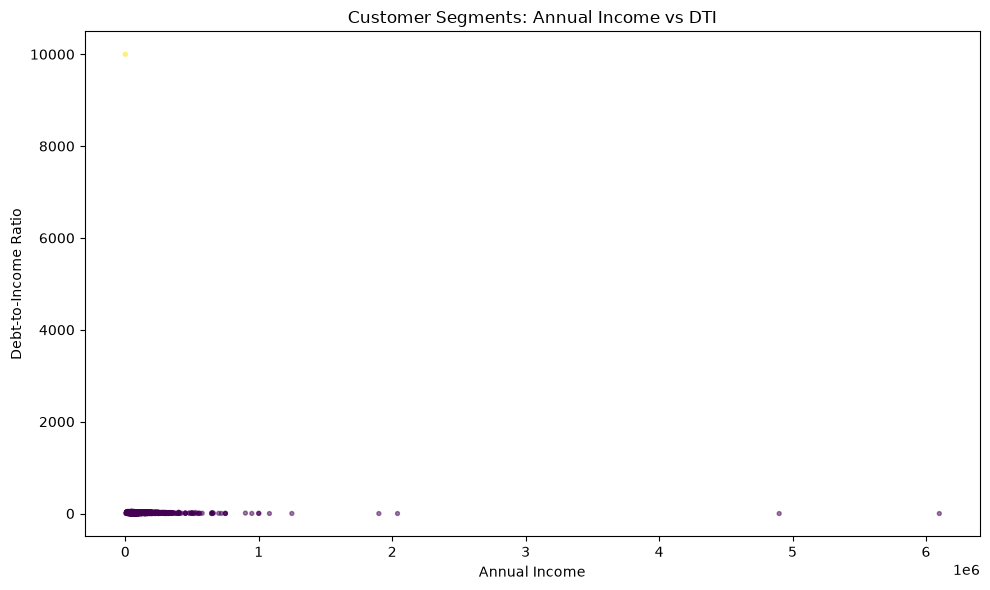

In [42]:

plt.figure(figsize=(10, 6))

plt.scatter(
    cluster_profile_data["annual_inc"],
    cluster_profile_data["dti"],
    c=cluster_profile_data["cluster"],
    s=8,
    alpha=0.5
)

plt.title("Customer Segments: Annual Income vs DTI")
plt.xlabel("Annual Income")
plt.ylabel("Debt-to-Income Ratio")

plt.tight_layout()
plt.show()


In [43]:

REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
MODELS_DIR = PROJECT_ROOT / "models"

FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

MODELS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Save classification results
classification_results.to_csv(
    REPORTS_DIR / "task3_classification_results.csv",
    index=False
)

# Save regression results
regression_results.to_csv(
    REPORTS_DIR / "task3_regression_results.csv",
    index=False
)

# Save clustering results
clustering_results.to_csv(
    REPORTS_DIR / "task3_clustering_results.csv",
    index=False
)

# Save cluster profiles
cluster_summary.to_csv(
    REPORTS_DIR / "task3_cluster_profiles.csv"
)

# Save top feature importance tables
top_5_rf.to_csv(
    REPORTS_DIR / "task3_random_forest_top_features.csv",
    index=False
)

top_5_xgb.to_csv(
    REPORTS_DIR / "task3_xgboost_top_features.csv",
    index=False
)

# Save fitted models
dump(
    logistic_pipeline,
    MODELS_DIR / "task3_logistic_pipeline.joblib"
)

dump(
    decision_tree_pipeline,
    MODELS_DIR / "task3_decision_tree_pipeline.joblib"
)

dump(
    random_forest_pipeline,
    MODELS_DIR / "task3_random_forest_pipeline.joblib"
)

dump(
    xgb_model,
    MODELS_DIR / "task3_xgboost_model.joblib"
)

dump(
    xgb_feature_engineer,
    MODELS_DIR / "task3_xgboost_feature_engineer.joblib"
)

dump(
    xgb_preprocessor,
    MODELS_DIR / "task3_xgboost_preprocessor.joblib"
)

dump(
    final_kmeans,
    MODELS_DIR / "task3_kmeans_model.joblib"
)

print("Task 3 results and models saved successfully!")


Task 3 results and models saved successfully!


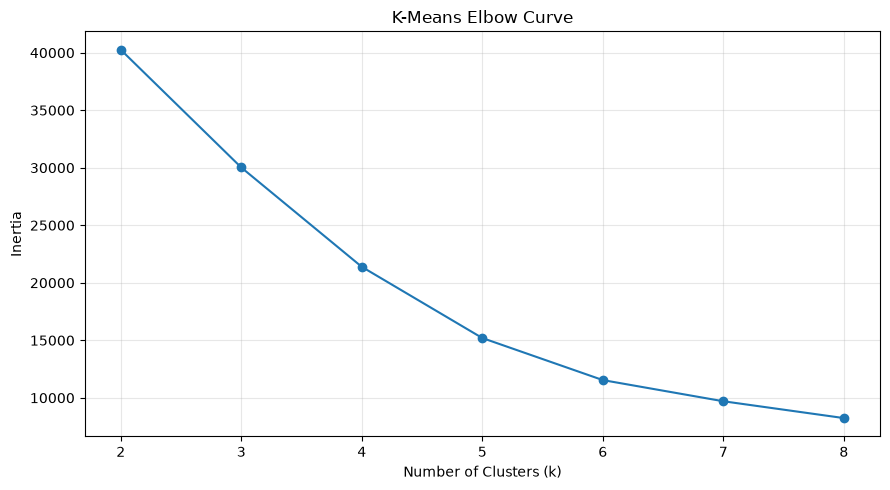

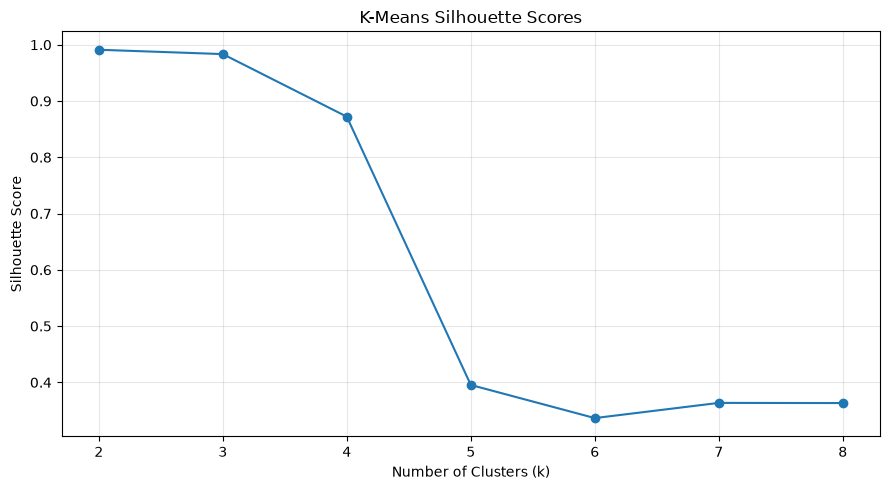

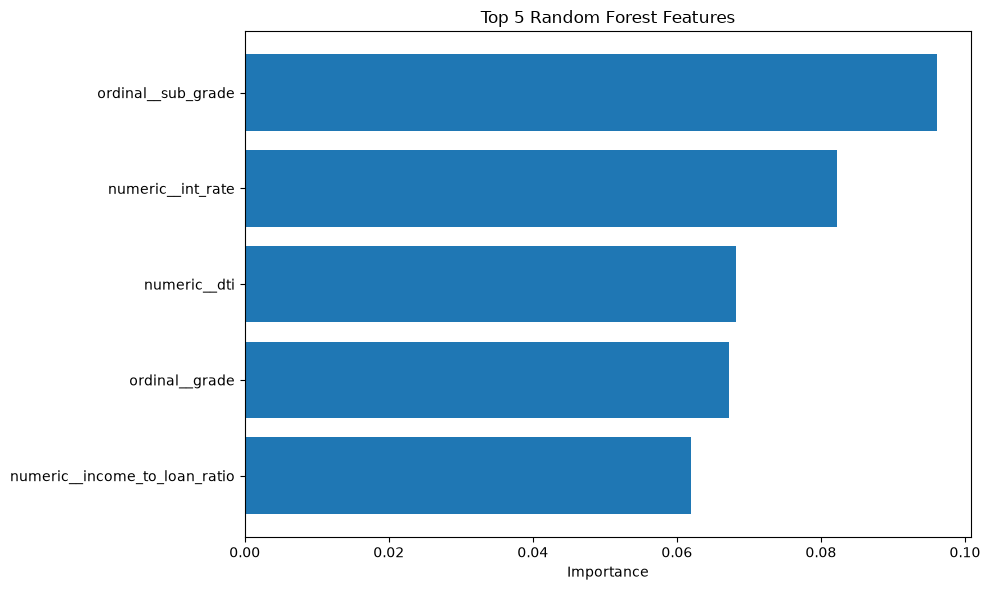

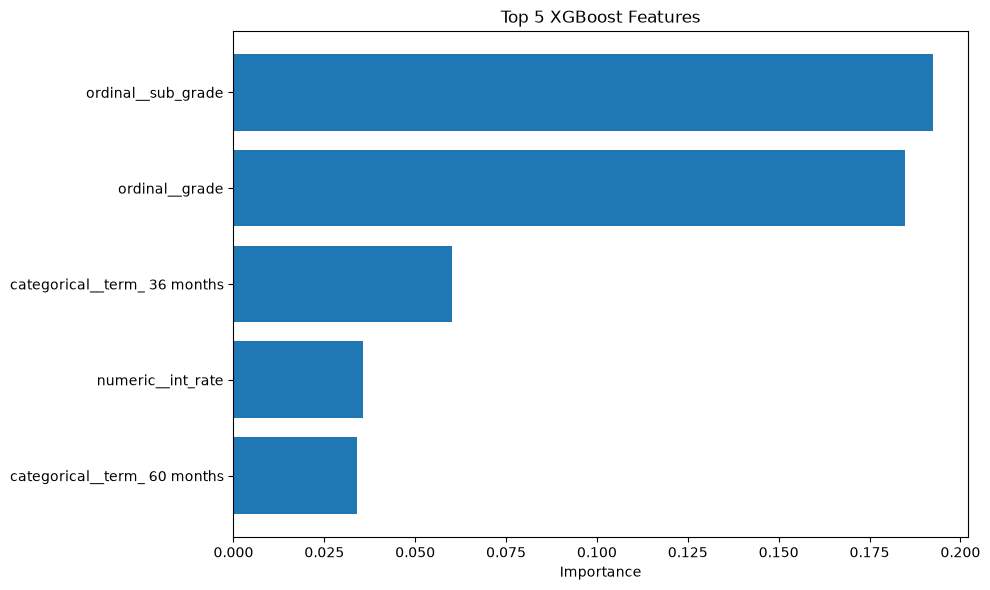

All Task 3 plots saved successfully!


In [44]:

# Elbow curve
plt.figure(figsize=(9, 5))

plt.plot(
    list(k_values),
    inertia_values,
    marker="o"
)

plt.title("K-Means Elbow Curve")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "task3_elbow_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Silhouette score plot
plt.figure(figsize=(9, 5))

plt.plot(
    list(k_values),
    silhouette_values,
    marker="o"
)

plt.title("K-Means Silhouette Scores")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "task3_silhouette_scores.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Random Forest feature importance
plt.figure(figsize=(10, 6))

plt.barh(
    top_5_rf["Feature"][::-1],
    top_5_rf["Importance"][::-1]
)

plt.title("Top 5 Random Forest Features")
plt.xlabel("Importance")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "task3_random_forest_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# XGBoost feature importance
plt.figure(figsize=(10, 6))

plt.barh(
    top_5_xgb["Feature"][::-1],
    top_5_xgb["Importance"][::-1]
)

plt.title("Top 5 XGBoost Features")
plt.xlabel("Importance")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "task3_xgboost_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("All Task 3 plots saved successfully!")
